# Transfer Learning with MobileNetV2

Instead of training a CNN from scratch, **re-use a network pre-trained on ImageNet** (1.2 million images, 1000 classes).

**Part 1 - use the pre-trained model as-is:** classify a goldfish photo (`goldfish.jpg`) and look up the class name in `ImageNetLabels.txt`.

**Part 2 - transfer learning:** drop MobileNetV2's classifier head, **freeze** its convolutional base, and train only a new 5-class head for the flower dataset.

Why it works: the early layers already detect general features (edges, textures, shapes) that are useful for almost any image task, so far less data and training time are needed.

> Files needed in this folder: `goldfish.jpg`, `ImageNetLabels.txt`. The flower dataset downloads automatically.

In [1]:
# Install TensorFlow Hub.
pip install tensorflow_hub

  Using cached tensorflow_hub-0.16.1-py2.py3-none-any.whl.metadata (1.3 kB)
  Using cached tf_keras-2.21.0-py3-none-any.whl.metadata (1.8 kB)
Using cached tensorflow_hub-0.16.1-py2.py3-none-any.whl (30 kB)
Using cached tf_keras-2.21.0-py3-none-any.whl (1.7 MB)

   ---------------------------------------- 0/2 [tf-keras]
   ---------------------------------------- 0/2 [tf-keras]
   ---------------------------------------- 0/2 [tf-keras]
   ---------------------------------------- 0/2 [tf-keras]
   ---------------------------------------- 0/2 [tf-keras]
   ---------------------------------------- 0/2 [tf-keras]
   ---------------------------------------- 0/2 [tf-keras]
   ---------------------------------------- 0/2 [tf-keras]
   ---------------------------------------- 0/2 [tf-keras]
   ---------------------------------------- 0/2 [tf-keras]
   ---------------------------------------- 0/2 [tf-keras]
   ---------------------------------------- 0/2 [tf-keras]
   ---------------------------

In [1]:
# Imports.
import numpy as np
import cv2
import PIL.Image as Image
import os
import matplotlib.pyplot as plt
import tensorflow as tf
import tensorflow_hub as hub
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.models import Sequential

C:\Users\HP\anaconda3\Lib\site-packages\tensorflow_hub\__init__.py:61: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import parse_version


In [2]:
# Load MobileNetV2 pre-trained on ImageNet, including its 1000-class classifier head (include_top=True).
IMAGE_SHAPE=(224,224)
base_model=tf.keras.applications.MobileNetV2(
    input_shape=IMAGE_SHAPE + (3,),
    include_top=True,
    weights='imagenet'
)

model=tf.keras.Sequential([base_model])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 1000)           │     3,538,984 │
│ (Functional)                    │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,538,984 (13.50 MB)

 Trainable params: 3,504,872 (13.37 MB)

 Non-trainable params: 34,112 (133.25 KB)

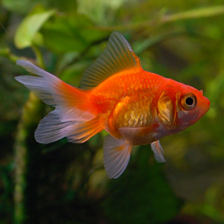

In [3]:
# Open the goldfish image and resize it to the 224x224 input size MobileNetV2 expects.
gold_fish = Image.open("goldfish.jpg").resize(IMAGE_SHAPE)
gold_fish

In [4]:
# Scale pixels to 0-1 and check the shape (224, 224, 3).
gold_fish=np.array(gold_fish)/255.0
gold_fish.shape

(224, 224, 3)

In [5]:
# Add a batch dimension with np.newaxis -> (1, 224, 224, 3), then predict: one probability per ImageNet class.
result=model.predict(gold_fish[np.newaxis,...])
result.shape

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step


(1, 1000)

In [6]:
# Index of the most probable class.
# NOTE: `result+1` adds 1 to every probability, which does not change which index is largest.
# The label file starts with a 'background' entry at index 0, so to look up the name you would add 1 to the INDEX: np.argmax(result) + 1.
predicted_label_index=np.argmax(result+1)
predicted_label_index

np.int64(1)

In [7]:
# Read the 1,001 ImageNet label names (index 0 is 'background').
image_labels=[]
with open("ImageNetLabels.txt","r") as f:
    image_labels=f.read().splitlines()
    image_labels[:5]

In [9]:
# Download the flower_photos dataset (5 classes) for the transfer-learning part.
dataset_url = "https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz"

data_dir=tf.keras.utils.get_file(
    'flower_photos',
    origin=dataset_url,
    cache_dir='.',
    untar=True
)

In [10]:
# Path to the dataset folder.
data_dir

'.\\datasets\\flower_photos'

In [14]:
# Convert to a pathlib.Path so we can use glob().
import pathlib
data_dir=pathlib.Path(data_dir)
data_dir

WindowsPath('datasets/flower_photos')

In [15]:
# List the first 5 image files.
list(data_dir.glob('*/*.jpg'))[:5]

[WindowsPath('datasets/flower_photos/daisy/100080576_f52e8ee070_n.jpg'),
 WindowsPath('datasets/flower_photos/daisy/10140303196_b88d3d6cec.jpg'),
 WindowsPath('datasets/flower_photos/daisy/10172379554_b296050f82_n.jpg'),
 WindowsPath('datasets/flower_photos/daisy/10172567486_2748826a8b.jpg'),
 WindowsPath('datasets/flower_photos/daisy/10172636503_21bededa75_n.jpg')]

In [16]:
# Count the images.
image_cont=len(list(data_dir.glob('*/*.jpg')))

In [17]:
# Print the image count.
print(image_cont)

3670


In [18]:
# All rose images.
roses=list(data_dir.glob('roses/*'))
roses[:5]

[WindowsPath('datasets/flower_photos/roses/10090824183_d02c613f10_m.jpg'),
 WindowsPath('datasets/flower_photos/roses/102501987_3cdb8e5394_n.jpg'),
 WindowsPath('datasets/flower_photos/roses/10503217854_e66a804309.jpg'),
 WindowsPath('datasets/flower_photos/roses/10894627425_ec76bbc757_n.jpg'),
 WindowsPath('datasets/flower_photos/roses/110472418_87b6a3aa98_m.jpg')]

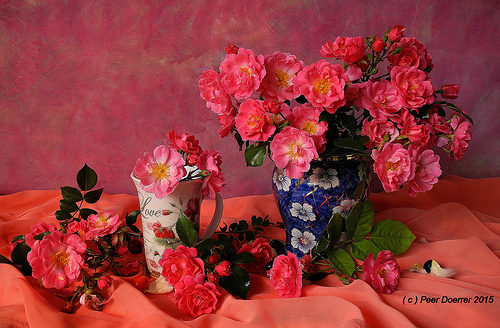

In [20]:
# Display one rose image.
import PIL
PIL.Image.open(str(roses[150]))

In [21]:
# All tulip images.
tulips=list(data_dir.glob('tulips/*'))
tulips[:5]

[WindowsPath('datasets/flower_photos/tulips/100930342_92e8746431_n.jpg'),
 WindowsPath('datasets/flower_photos/tulips/10094729603_eeca3f2cb6.jpg'),
 WindowsPath('datasets/flower_photos/tulips/10094731133_94a942463c.jpg'),
 WindowsPath('datasets/flower_photos/tulips/10128546863_8de70c610d.jpg'),
 WindowsPath('datasets/flower_photos/tulips/10163955604_ae0b830975_n.jpg')]

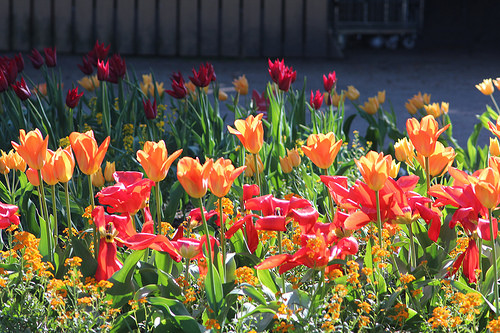

In [23]:
# Display one tulip image.
PIL.Image.open(str(tulips[110]))

In [24]:
# Dictionary: class name -> list of image paths.
flowers_images_dict={
    'roses': list(data_dir.glob('roses/*')),
    'daisy':list(data_dir.glob('daisy/*')),
    'dandelion':list(data_dir.glob('dandelion/*')),
    'sunflowers':list(data_dir.glob('sunflowers/*')),
    'tulips':list(data_dir.glob('tulips/*')),
}

In [25]:
# Dictionary: class name -> numeric label.
flowers_labels_dict={
    'roses': 0,
    'daisy': 1,
    'dandelion': 2,
    'sunflowers':3,
    'tulips':4,
}

In [26]:
# OpenCV for reading and resizing images.
import cv2

In [30]:
# Build X and y; every image is resized to 224x224 (MobileNetV2's input size).
X,y=[],[]
for flower_name,images in flowers_images_dict.items():
    for image in images:
        img=cv2.imread(str(image))
        resized_img=cv2.resize(img,(224,224))
        X.append(resized_img)
        y.append(flowers_labels_dict[flower_name])

In [31]:
# Convert lists to NumPy arrays.
X=np.array(X)
y=np.array(y)

In [32]:
# Train/test split with a fixed random_state.
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,random_state=0)

In [33]:
# Scale pixel values from 0-255 to 0-1.
X_train_scaled=X_train/255
X_test_scaled=X_test/255

In [41]:
# Transfer-learning model: MobileNetV2 without its classifier (include_top=False) acts as a feature extractor;
# pooling='avg' gives one 1280-value feature vector per image. Freeze it and train only a new Dense head for 5 flower classes.
# NOTE 1: `trainable=false` (lowercase) raises a NameError - Python's boolean is `False`.
# NOTE 2: the Dense layer already applies softmax, but the loss in the next cell uses from_logits=True (which expects raw scores).
# Use either softmax + from_logits=False, or no activation + from_logits=True.
import tensorflow as tf

num_of_flowers=5
base_model=tf.keras.applications.MobileNetV2(
    input_shape=(224,224,3),
    include_top=False,
    weights='imagenet',
    pooling='avg'
)

base_model.trainable=false
model=tf.keras.Sequential([
    base_model,
    tf.keras.layers.Dense(num_of_flowers,activation='softmax')
])
model.summary()

Exception: URL fetch failure on https://storage.googleapis.com/tensorflow/keras-applications/mobilenet_v2/mobilenet_v2_weights_tf_dim_ordering_tf_kernels_1.0_224_no_top.h5: None -- [Errno 11001] getaddrinfo failed

In [ ]:
# Train only the new head for 5 epochs (the frozen base is not updated).
model.compile(
    optimizer="adam",
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=['acc'])
model.fit(X_train_scaled,y_train,epochs=5)